# Fase 2 — Preprocesamiento, ingeniería de variables y modelo base
## Predict Students' Dropout and Academic Success (UCI, id 697)

**Objetivo:** preparar el dataset para modelado de forma reproducible y **sin fuga de datos (data leakage)**: tratamiento justificado de faltantes y atípicos, ingeniería de variables, codificación, escalamiento, partición estratificada, manejo del desbalance y modelo base (baseline).

**Principio rector:** *todo lo que se aprende de los datos (límites de winsorización, categorías, medias, desviaciones, sobremuestreo) se ajusta únicamente con el conjunto de entrenamiento.* Validación y prueba solo se transforman.

**Momento de predicción definido:** *final del primer semestre*. Se usan variables disponibles al ingreso y las del 1.er semestre; **se excluyen las del 2.º semestre** (fuga temporal para una alerta temprana), tal como advierte el cierre metodológico del EDA. Las variables del 2.º semestre solo se usan en un análisis de sensibilidad claramente separado (sección 12).

> Los resultados y las interpretaciones deben redactarse a partir de las salidas de este cuaderno.

## 1. Entorno y carga de datos

In [1]:
%pip -q install ucimlrepo imbalanced-learn statsmodels

Note: you may need to restart the kernel to use updated packages.


In [2]:
import re, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from IPython.display import display

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, log_loss,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")
SEED = 42
pd.set_option("display.max_columns", 100); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
OUT = Path("output_fase2"); OUT.mkdir(exist_ok=True)

# Paleta apta para daltonismo (Okabe-Ito) con color fijo por clase
PAL = {"Dropout": "#D55E00", "Enrolled": "#E69F00", "Graduate": "#0072B2"}
CLASSES = ["Dropout", "Enrolled", "Graduate"]
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
def savefig(name):
    plt.tight_layout(); plt.savefig(OUT / name, dpi=200, bbox_inches="tight"); plt.show()

In [3]:
# Carga: 1) CSV local (data.csv de UCI, separador ';') si existe; 2) descarga con ucimlrepo.
CANON = ["Marital Status","Application mode","Application order","Course","Daytime/evening attendance",
 "Previous qualification","Previous qualification (grade)","Nacionality","Mother's qualification",
 "Father's qualification","Mother's occupation","Father's occupation","Admission grade","Displaced",
 "Educational special needs","Debtor","Tuition fees up to date","Gender","Scholarship holder",
 "Age at enrollment","International","Curricular units 1st sem (credited)","Curricular units 1st sem (enrolled)",
 "Curricular units 1st sem (evaluations)","Curricular units 1st sem (approved)","Curricular units 1st sem (grade)",
 "Curricular units 1st sem (without evaluations)","Curricular units 2nd sem (credited)",
 "Curricular units 2nd sem (enrolled)","Curricular units 2nd sem (evaluations)","Curricular units 2nd sem (approved)",
 "Curricular units 2nd sem (grade)","Curricular units 2nd sem (without evaluations)","Unemployment rate",
 "Inflation rate","GDP","Target"]
def _norm(c): return re.sub(r"\s+", " ", str(c).replace("\ufeff","")).strip().lower()
LOCAL = next((p for p in [Path("data.csv"), Path("/content/data.csv")] if p.exists()), None)
if LOCAL is not None:
    df = pd.read_csv(LOCAL, sep=None, engine="python"); FUENTE = f"CSV local ({LOCAL})"
else:
    from ucimlrepo import fetch_ucirepo
    d = fetch_ucirepo(id=697)
    df = pd.concat([d.data.features, d.data.targets], axis=1); FUENTE = "UCI vía ucimlrepo (id=697)"
mapa = {_norm(c): c for c in CANON}
df.columns = [mapa.get(_norm(c), str(c).strip()) for c in df.columns]
faltan = set(CANON) - set(df.columns)
assert not faltan, f"Columnas ausentes: {faltan}"
df = df[CANON].copy()
df["Target"] = df["Target"].astype(str).str.strip()
print("Fuente:", FUENTE); print("Dimensiones:", df.shape)
print(df["Target"].value_counts())

Fuente: CSV local (data.csv)
Dimensiones: (4424, 37)
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


## 2. Definición del problema y partición estratificada (antes de cualquier ajuste)

- **Problema:** clasificación multiclase (`Dropout`, `Enrolled`, `Graduate`).
- **Partición:** 70 % entrenamiento / 15 % validación / 15 % prueba, **estratificada por `Target`**. La partición se hace *antes* de calcular cualquier estadístico aprendido. La prueba solo se usa una vez, al final.

,n,pct_total
Entrenamiento,3096,69.9819
Validación,664,15.0090
Prueba,664,15.0090
Total,4424,100.0000


,Entrenamiento,Validación,Prueba,Total
Target,,,,
Dropout,32.1100,32.0800,32.2300,32.1200
Enrolled,17.9600,17.9200,17.9200,17.9500
Graduate,49.9400,50.0000,49.8500,49.9300


,Entrenamiento,Validación,Prueba
Target,,,
Dropout,994,213,214
Enrolled,556,119,119
Graduate,1546,332,331


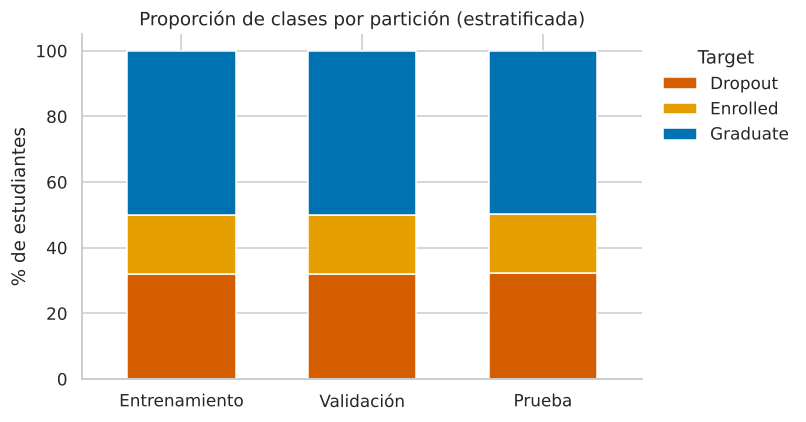

In [4]:
y_all = df["Target"]
X_all = df.drop(columns="Target")
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X_all, y_all, test_size=0.30, stratify=y_all, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

part = pd.DataFrame({
  "n": [len(y_tr), len(y_va), len(y_te), len(y_all)],
  "pct_total": [len(y_tr)/len(y_all)*100, len(y_va)/len(y_all)*100, len(y_te)/len(y_all)*100, 100.0]},
  index=["Entrenamiento","Validación","Prueba","Total"])
display(part)
prop = pd.DataFrame({"Entrenamiento": y_tr.value_counts(normalize=True), "Validación": y_va.value_counts(normalize=True),
                     "Prueba": y_te.value_counts(normalize=True), "Total": y_all.value_counts(normalize=True)}).loc[CLASSES]*100
display(prop.round(2))
cnt = pd.DataFrame({"Entrenamiento": y_tr.value_counts(), "Validación": y_va.value_counts(), "Prueba": y_te.value_counts()}).loc[CLASSES]
display(cnt)

fig, ax = plt.subplots(figsize=(7.5, 4))
prop.drop(columns="Total").T.plot(kind="bar", stacked=True, ax=ax, color=[PAL[c] for c in CLASSES], width=0.6, edgecolor="white")
ax.set_ylabel("% de estudiantes"); ax.set_title("Proporción de clases por partición (estratificada)")
ax.legend(title="Target", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False); plt.xticks(rotation=0)
savefig("f1_particion_estratificada.png")

## 3. Valores faltantes: diagnóstico del mecanismo (MCAR / MAR / MNAR)

Regla del proyecto: **no se imputa sin analizar el mecanismo de falta.** El análisis se hace sobre el conjunto de entrenamiento y en tres niveles:

1. **Faltantes explícitos** (`NaN`) por partición.
2. **Faltantes implícitos:** valores centinela o ceros que en realidad significan «no aplica / no evaluado».
3. **Mecanismo:** si existe un patrón de ausencia, se contrasta con las covariables observadas (indicio de MAR) y con `Target` (indicio de falta informativa / MNAR).

In [5]:
# 3.1 Faltantes explícitos
nan_tab = pd.DataFrame({"entrenamiento": X_tr.isna().sum().sum(), "validación": X_va.isna().sum().sum(),
                        "prueba": X_te.isna().sum().sum()}, index=["celdas_NaN"])
display(nan_tab)
print("Filas duplicadas en entrenamiento:", int(X_tr.duplicated().sum()))

,entrenamiento,validación,prueba
celdas_NaN,0,0,0


Filas duplicadas en entrenamiento: 0


In [6]:
# 3.2 Faltantes implícitos: ceros estructurales en las notas de unidades curriculares
rows = []
for s, tag in [("1st sem","1.er semestre"),("2nd sem","2.º semestre")]:
    g = X_tr[f"Curricular units {s} (grade)"]; ev = X_tr[f"Curricular units {s} (evaluations)"]
    en = X_tr[f"Curricular units {s} (enrolled)"]
    rows.append({"semestre": tag,
        "nota=0": int((g==0).sum()),
        "nota=0 y evaluaciones=0": int(((g==0)&(ev==0)).sum()),
        "nota=0 y evaluaciones>0": int(((g==0)&(ev>0)).sum()),
        "nota>0 y evaluaciones=0": int(((g>0)&(ev==0)).sum()),
        "matriculadas=0": int((en==0).sum())})
imp = pd.DataFrame(rows).set_index("semestre"); display(imp)

# Verificaciones adicionales sobre el cero estructural de la nota
g1 = X_tr["Curricular units 1st sem (grade)"]; a1 = X_tr["Curricular units 1st sem (approved)"]
print("1S: nota=0 y aprobadas=0:", int(((g1==0)&(a1==0)).sum()), "| nota=0 y aprobadas>0:", int(((g1==0)&(a1>0)).sum()), "| nota>0 y aprobadas=0:", int(((g1>0)&(a1==0)).sum()))
print("1S: nota mínima positiva:", g1[g1>0].min(), "| n con 0<nota<10:", int(((g1>0)&(g1<10)).sum()))
e1 = X_tr["Curricular units 1st sem (enrolled)"]; e2 = X_tr["Curricular units 2nd sem (enrolled)"]
print("matriculadas 1S=0 y 2S=0:", int(((e1==0)&(e2==0)).sum()), "| matriculadas 1S=0 y 2S>0:", int(((e1==0)&(e2>0)).sum()), "| matriculadas 1S>0 y 2S=0:", int(((e1>0)&(e2==0)).sum()))

# Centinelas en otras variables numéricas (mínimos y conteo de ceros)
num_chk = ["Age at enrollment","Previous qualification (grade)","Admission grade","Application order",
           "Unemployment rate","Inflation rate","GDP"]
display(pd.DataFrame({"min": X_tr[num_chk].min(), "max": X_tr[num_chk].max(), "n_ceros": (X_tr[num_chk]==0).sum()}))

,nota=0,nota=0 y evaluaciones=0,nota=0 y evaluaciones>0,nota>0 y evaluaciones=0,matriculadas=0
semestre,,,,,
1.er semestre,511,261,250,0,137
2.º semestre,624,293,331,0,137


1S: nota=0 y aprobadas=0: 511 | nota=0 y aprobadas>0: 0 | nota>0 y aprobadas=0: 0
1S: nota mínima positiva: 10.0 | n con 0<nota<10: 0
matriculadas 1S=0 y 2S=0: 137 | matriculadas 1S=0 y 2S>0: 0 | matriculadas 1S>0 y 2S=0: 0


,min,max,n_ceros
Age at enrollment,17.0000,70.0000,0
Previous qualification (grade),95.0000,190.0000,0
Admission grade,95.0000,190.0000,0
Application order,0.0000,9.0000,1
Unemployment rate,7.6000,16.2000,0
Inflation rate,-0.8000,3.7000,0
GDP,-4.0600,3.5100,0


Prevalencia del patrón 'sin evaluaciones 1S' en entrenamiento: 8.43%
Tabla ind x Target:


Target,Dropout,Enrolled,Graduate
sin_evaluaciones_1S,,,
0,813,535,1487
1,181,21,59


chi2=181.37, gl=2, p=4.139e-40, V de Cramér=0.242


Target,Dropout,Enrolled,Graduate
sin_evaluaciones_1S,,,
0,28.7000,18.9000,52.5000
1,69.3000,8.0000,22.6000


AUC (CV) de predecir el patrón con covariables observadas: 0.642


,Age at enrollment,Admission grade,Debtor,Tuition fees up to date,Scholarship holder
ind,,,,,
0,23.2360,126.5420,0.1100,0.8850,0.2630
1,23.0000,130.9740,0.1110,0.8350,0.1420


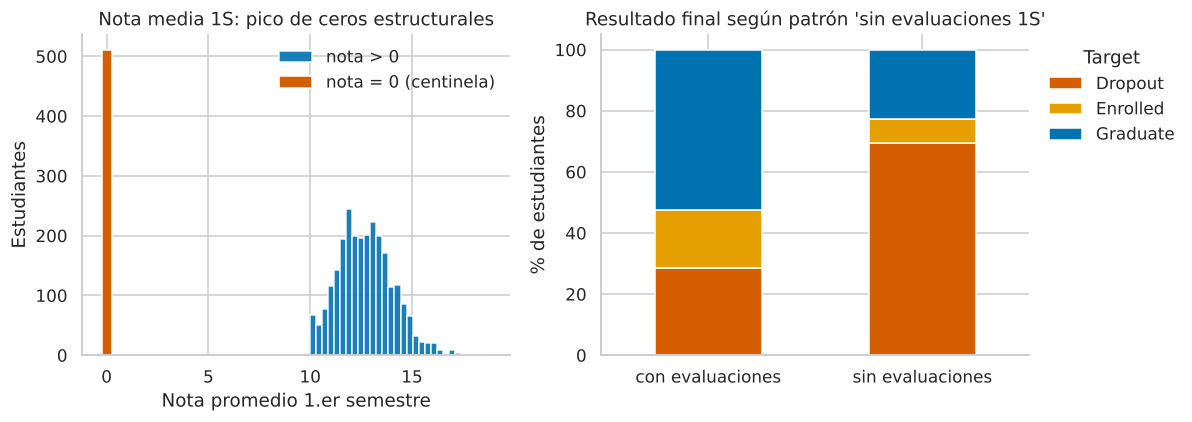

In [7]:
# 3.3 Mecanismo del patrón estructural «sin evaluaciones» (1.er semestre), solo sobre entrenamiento
ev1 = "Curricular units 1st sem (evaluations)"
ind = (X_tr[ev1] == 0).astype(int).rename("sin_evaluaciones_1S")
print("Prevalencia del patrón 'sin evaluaciones 1S' en entrenamiento: %.2f%%" % (ind.mean()*100))

# (a) Relación con Target (¿falta informativa? -> indicio MNAR/estructural)
ct = pd.crosstab(ind, y_tr)
chi2, p, dof, _ = stats.chi2_contingency(ct)
V = np.sqrt(chi2/(ct.values.sum()*(min(ct.shape)-1)))
print("Tabla ind x Target:"); display(ct)
print(f"chi2={chi2:.2f}, gl={dof}, p={p:.4g}, V de Cramér={V:.3f}")
display((pd.crosstab(ind, y_tr, normalize="index")*100).round(1))

# (b) ¿Se predice con covariables observadas? (AUC por CV; indicio MAR)
from sklearn.ensemble import RandomForestClassifier
cov = ["Age at enrollment","Admission grade","Previous qualification (grade)","Application order",
       "Debtor","Tuition fees up to date","Scholarship holder","Gender","Displaced","Daytime/evening attendance"]
if ind.nunique() == 2 and ind.sum() >= 20:
    skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
    pr = cross_val_predict(RandomForestClassifier(200, max_depth=5, random_state=SEED, n_jobs=-1),
                           X_tr[cov], ind, cv=skf, method="predict_proba")[:,1]
    print(f"AUC (CV) de predecir el patrón con covariables observadas: {roc_auc_score(ind, pr):.3f}")
else:
    print("Patrón demasiado raro para estimar el mecanismo con covariables.")

# (c) Diferencia de covariables entre grupos
display(X_tr.assign(ind=ind).groupby("ind")[["Age at enrollment","Admission grade","Debtor","Tuition fees up to date","Scholarship holder"]].mean().round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
nz = X_tr["Curricular units 1st sem (grade)"]
axes[0].hist(nz[nz>0], bins=30, color="#0072B2", alpha=.9, label="nota > 0"); 
axes[0].bar(0, (nz==0).sum(), width=0.5, color="#D55E00", label="nota = 0 (centinela)")
axes[0].set_title("Nota media 1S: pico de ceros estructurales"); axes[0].set_xlabel("Nota promedio 1.er semestre"); axes[0].set_ylabel("Estudiantes"); axes[0].legend(frameon=False)
(pd.crosstab(ind, y_tr, normalize="index")*100).rename(index={0:"con evaluaciones",1:"sin evaluaciones"})[CLASSES].plot(kind="bar", stacked=True, ax=axes[1], color=[PAL[c] for c in CLASSES], edgecolor="white")
axes[1].set_title("Resultado final según patrón 'sin evaluaciones 1S'"); axes[1].set_ylabel("% de estudiantes"); axes[1].set_xlabel(""); plt.setp(axes[1].get_xticklabels(), rotation=0)
axes[1].legend(title="Target", bbox_to_anchor=(1.01,1), loc="upper left", frameon=False)
savefig("f2_faltantes_estructurales.png")

In [8]:
# 3.4 Decisión (derivada de los resultados anteriores)
total_nan = int(X_tr.isna().sum().sum() + X_va.isna().sum().sum() + X_te.isna().sum().sum())
print("Total de NaN en todo el dataset:", total_nan)
if total_nan == 0:
    print("DECISIÓN: no existen faltantes explícitos -> no se elimina ni imputa ninguna celda (imputar sería inventar datos).")
else:
    print("ATENCIÓN: existen NaN; se requiere definir imputación según el mecanismo.")
print("Los ceros estructurales NO se imputan: se conservan y se hace explícita su señal con un indicador binario (sección 5).")

Total de NaN en todo el dataset: 0
DECISIÓN: no existen faltantes explícitos -> no se elimina ni imputa ninguna celda (imputar sería inventar datos).
Los ceros estructurales NO se imputan: se conservan y se hace explícita su señal con un indicador binario (sección 5).


### Matriz de decisión técnica (eliminación vs. imputación)

| Opción | ¿Aplica aquí? | Razonamiento |
|---|---|---|
| Eliminación (listwise) | No aplica | Sin `NaN` explícitos no hay filas que eliminar; eliminar los casos «sin evaluaciones» sesgaría la muestra hacia estudiantes que sí rindieron evaluaciones y quitaría justamente a quienes tienen mayor riesgo. |
| Media / mediana | No | Sustituir el cero estructural por una nota central fabricaría un rendimiento inexistente. |
| KNNImputer / IterativeImputer | No | Presuponen MAR y valores que existen pero no se observaron; aquí el valor **no existe** (no hubo evaluación). |
| **Conservar + indicador binario** | **Sí** | Preserva la información (ausencia informativa) y deja al modelo usarla sin inventar datos. |

Si en una versión futura apareciesen `NaN`, el flujo debería incluir un imputador **dentro del Pipeline** (ajustado solo con entrenamiento) tras repetir este análisis de mecanismo.

## 4. Valores atípicos: diagnóstico y tratamiento

El EDA ya identificó candidatos con IQR y Z-score. Aquí se decide el tratamiento **calculando todo sobre entrenamiento**:

- **No se eliminan filas:** los valores extremos (p. ej. edades altas o muchas unidades) son plausibles en educación superior y corresponden a poblaciones reales (estudiantes adultos).
- **Winsorización** en los percentiles 1 y 99 (límites aprendidos en entrenamiento) para variables continuas y de conteo.
- **Transformación log(1+x)** cuando, tras winsorizar, la asimetría de la variable en entrenamiento supera 1 **y** la transformación reduce la asimetría absoluta (si la empeora, no se aplica).

In [9]:
cont_cols = ["Application order","Age at enrollment","Previous qualification (grade)","Admission grade",
 "Curricular units 1st sem (credited)","Curricular units 1st sem (enrolled)","Curricular units 1st sem (evaluations)",
 "Curricular units 1st sem (approved)","Curricular units 1st sem (grade)","Curricular units 1st sem (without evaluations)",
 "Unemployment rate","Inflation rate","GDP"]
def iqr_tab(d, cols):
    r=[]
    for c in cols:
        q1,q3=d[c].quantile([.25,.75]); i=q3-q1; li,ls=q1-1.5*i,q3+1.5*i
        n=int(((d[c]<li)|(d[c]>ls)).sum())
        r.append({"variable":c,"asimetria":d[c].skew(),"p1":d[c].quantile(.01),"p99":d[c].quantile(.99),
                  "max":d[c].max(),"n_atipicos_IQR":n,"pct_IQR":n/len(d)*100})
    return pd.DataFrame(r).set_index("variable")
t_out = iqr_tab(X_tr, cont_cols); display(t_out)
t_out.to_csv(OUT/"outliers_entrenamiento.csv", encoding="utf-8-sig")

,asimetria,p1,p99,max,n_atipicos_IQR,pct_IQR
variable,,,,,,
Application order,1.8896,1.0000,6.0000,9.0000,370,11.9509
Age at enrollment,2.0815,18.0000,51.0000,70.0000,307,9.9160
Previous qualification (grade),0.2998,100.0000,170.0000,190.0000,116,3.7468
Admission grade,0.5294,98.6950,166.0450,190.0000,57,1.8411
Curricular units 1st sem (credited),4.1887,0.0000,13.0000,20.0000,409,13.2106
Curricular units 1st sem (enrolled),1.5882,0.0000,17.0000,26.0000,303,9.7868
Curricular units 1st sem (evaluations),0.8867,0.0000,21.0000,45.0000,108,3.4884
Curricular units 1st sem (approved),0.7721,0.0000,14.0000,26.0000,122,3.9406
Curricular units 1st sem (grade),-1.5480,0.0000,16.0056,18.8750,517,16.6990


Variables con asimetría > 1 tras winsorizar (se aplicará log1p):
['Application order', 'Age at enrollment', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (without evaluations)']


,asim_original,asim_winsor,asim_winsor+log1p
Application order,1.8896,1.8658,1.4159
Age at enrollment,2.0815,1.9307,1.4812
Previous qualification (grade),0.2998,0.1781,0.1781
Admission grade,0.5294,0.3980,0.3980
Curricular units 1st sem (credited),4.1887,3.7902,2.7310
Curricular units 1st sem (enrolled),1.5882,1.1701,1.1701
Curricular units 1st sem (evaluations),0.8867,0.3182,0.3182
Curricular units 1st sem (approved),0.7721,0.2495,0.2495
Curricular units 1st sem (grade),-1.5480,-1.5583,-1.5583
Curricular units 1st sem (without evaluations),7.7484,4.5554,3.9386


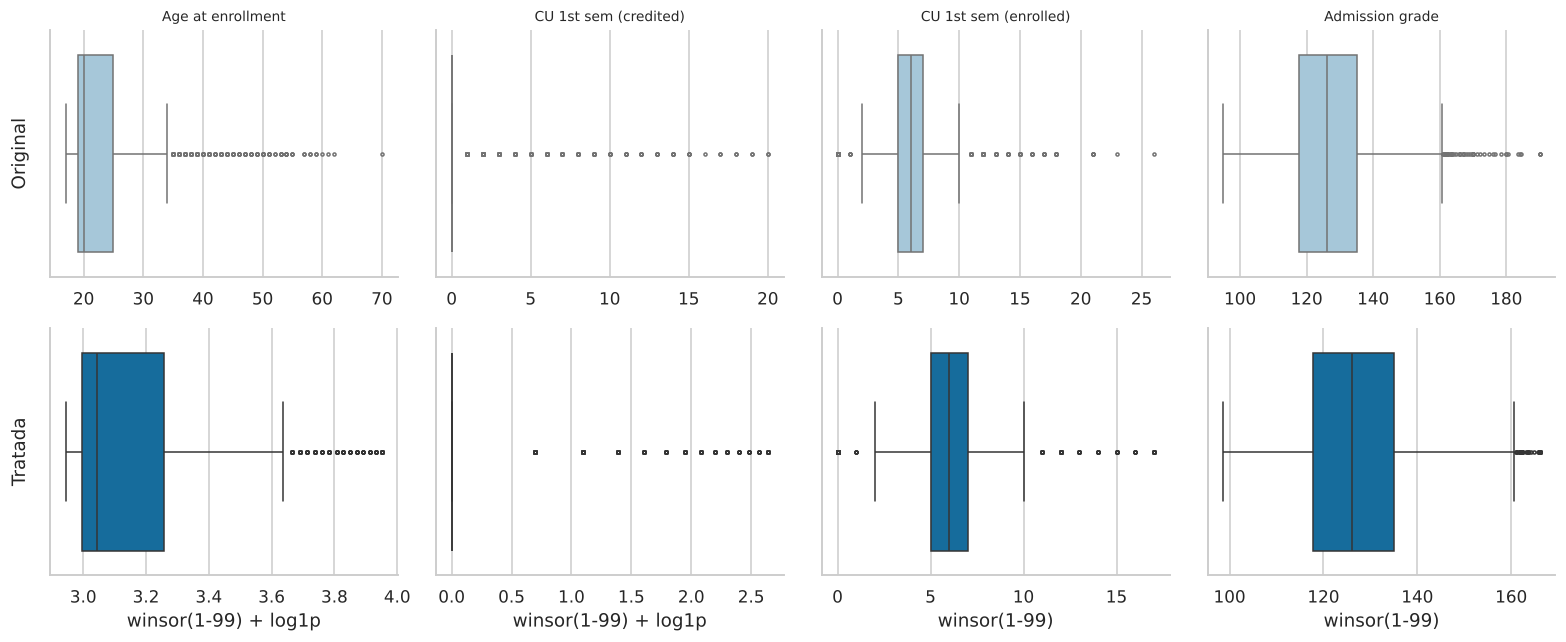

In [10]:
class Winsorizer(BaseEstimator, TransformerMixin):
    """Recorta por percentiles aprendidos SOLO en fit (entrenamiento)."""
    def __init__(self, lower=1, upper=99): self.lower, self.upper = lower, upper
    def fit(self, X, y=None):
        X = np.asarray(X, float)
        self.lo_ = np.nanpercentile(X, self.lower, axis=0); self.hi_ = np.nanpercentile(X, self.upper, axis=0); return self
    def transform(self, X): return np.clip(np.asarray(X, float), self.lo_, self.hi_)
    def get_feature_names_out(self, input_features=None): return np.asarray(input_features)

# Asimetría tras winsorizar (límites de entrenamiento) -> selección de variables a transformar con log1p
w = Winsorizer(1,99).fit(X_tr[cont_cols])
Xw = pd.DataFrame(w.transform(X_tr[cont_cols]), columns=cont_cols, index=X_tr.index)
skew_after = Xw.skew()
# log1p solo si (i) la asimetría tras winsorizar > 1 y (ii) la transformación REDUCE la asimetría absoluta
LOG_COLS = [c for c in cont_cols if skew_after[c] > 1 and Xw[c].min() >= 0 and abs(np.log1p(Xw[c]).skew()) < abs(skew_after[c])]
print("Variables con asimetría > 1 tras winsorizar (se aplicará log1p):"); print(LOG_COLS)
cmp = pd.DataFrame({"asim_original": X_tr[cont_cols].skew(), "asim_winsor": skew_after,
                    "asim_winsor+log1p": Xw.apply(lambda s: np.log1p(s).skew() if s.name in LOG_COLS else s.skew())})
display(cmp)
cmp.to_csv(OUT/"asimetria_antes_despues.csv", encoding="utf-8-sig")

# Figura: antes vs. después en variables ilustrativas
ej = [c for c in ["Age at enrollment","Curricular units 1st sem (credited)","Curricular units 1st sem (enrolled)","Admission grade"] if c in cont_cols]
fig, axes = plt.subplots(2, len(ej), figsize=(3.6*len(ej), 6))
for j, c in enumerate(ej):
    sns.boxplot(x=X_tr[c], ax=axes[0,j], color="#9ecae1", fliersize=2); axes[0,j].set_title(c.replace("Curricular units ","CU "), fontsize=9); axes[0,j].set_xlabel("")
    v = Xw[c]; v = np.log1p(v) if c in LOG_COLS else v
    sns.boxplot(x=v, ax=axes[1,j], color="#0072B2", fliersize=2); axes[1,j].set_xlabel("winsor(1-99)" + (" + log1p" if c in LOG_COLS else ""))
axes[0,0].set_ylabel("Original"); axes[1,0].set_ylabel("Tratada")
savefig("f3_atipicos_antes_despues.png")

## 5. Ingeniería de variables (conocimiento del dominio)

Las variables derivadas se calculan **fila a fila** (sin estadísticos globales), por lo que aplicarlas a cada partición por separado no introduce fuga. Solo usan información disponible al final del 1.er semestre.

| Variable derivada | Definición | Respaldo en el dominio |
|---|---|---|
| `tasa_aprobacion_1s` | aprobadas / matriculadas (1S) | El avance académico temprano es uno de los predictores más sólidos de permanencia (Tinto; Bean). Normaliza la carga distinta de cada estudiante. |
| `tasa_exito_eval_1s` | aprobadas / evaluaciones (1S) | Eficiencia: cuántas de las evaluaciones presentadas se convierten en aprobación. |
| `prop_convalidadas_1s` | créditos convalidados / (convalidados + matriculadas) | Distingue a quienes llegan con reconocimiento de estudios previos (transferencia), que tienen otra trayectoria. |
| `riesgo_financiero` | `Debtor` + (1 − `Tuition fees up to date`), valor 0–2 | La tensión financiera (deuda, matrícula atrasada) se asocia con abandono; se condensa en un índice. |
| `dif_nota_ingreso_previa` | nota de admisión − nota de titulación previa | Mide si el desempeño en el ingreso estuvo por encima o por debajo del historial previo. |
| `sin_evaluaciones_1s`, `sin_carga_1s` | indicadores (evaluaciones = 0; matriculadas = 0) | Hacen explícita la ausencia estructural analizada en la sección 3 en lugar de imputarla. |

Cuando el denominador es 0 la razón no está definida; se fija en 0 y se **acompaña del indicador** correspondiente para no confundir «no aplica» con «0 % de éxito».

NaN/inf en derivadas (entrenamiento): 0 0


,mediana_Dropout,mediana_Enrolled,mediana_Graduate,Kruskal_H,valor_p,epsilon2
variable,,,,,,
tasa_aprobacion_1s,0.3333,0.8000,1.0000,"1,245.0209",0.0000,0.4023
tasa_exito_eval_1s,0.1847,0.5000,0.8571,"1,156.0529",0.0000,0.3735
prop_convalidadas_1s,0.0000,0.0000,0.0000,0.3271,0.8491,0.0001
riesgo_financiero,0.0000,0.0000,0.0000,520.7493,0.0000,0.1683
dif_nota_ingreso_previa,-5.0000,-4.9000,-5.4000,1.3204,0.5168,0.0004


Target,Dropout,Enrolled,Graduate
riesgo_financiero,,,
0,604,485,1469
1,239,56,71
2,151,15,6


Target,Dropout,Enrolled,Graduate
riesgo_financiero,,,
0,23.6000,19.0000,57.4000
1,65.3000,15.3000,19.4000
2,87.8000,8.7000,3.5000


Indicador sin_evaluaciones_1s: n con valor 1 = 261 (8.43% del entrenamiento)


Target,Dropout,Enrolled,Graduate
sin_evaluaciones_1s,,,
0,813,535,1487
1,181,21,59


Target,Dropout,Enrolled,Graduate
sin_evaluaciones_1s,,,
0,28.7000,18.9000,52.5000
1,69.3000,8.0000,22.6000


Indicador sin_carga_1s: n con valor 1 = 137 (4.43% del entrenamiento)


Target,Dropout,Enrolled,Graduate
sin_carga_1s,,,
0,937,535,1487
1,57,21,59


Target,Dropout,Enrolled,Graduate
sin_carga_1s,,,
0,31.7000,18.1000,50.3000
1,41.6000,15.3000,43.1000


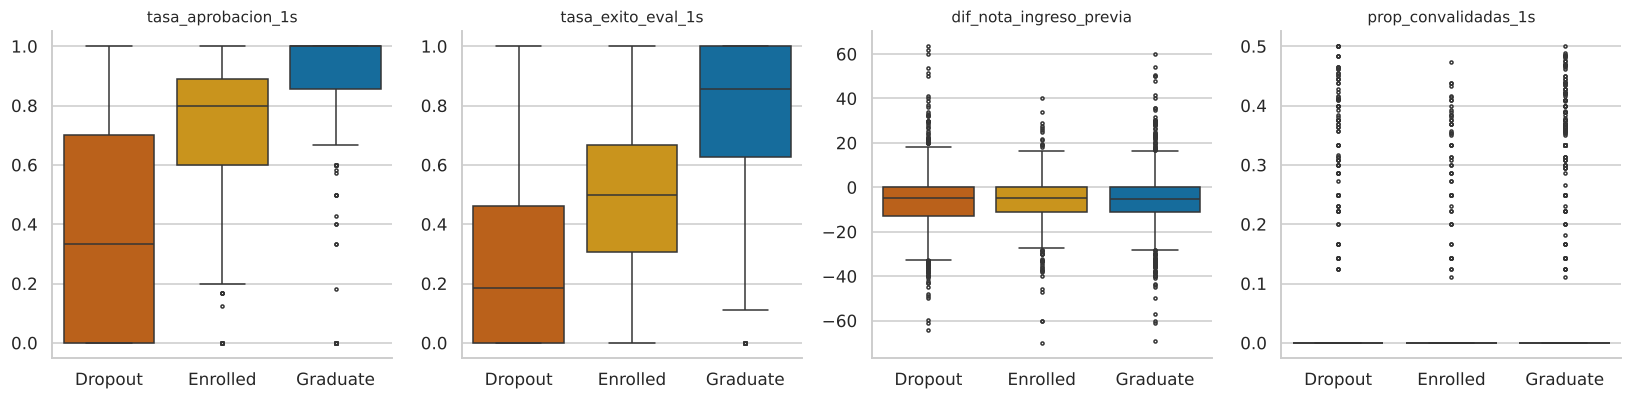

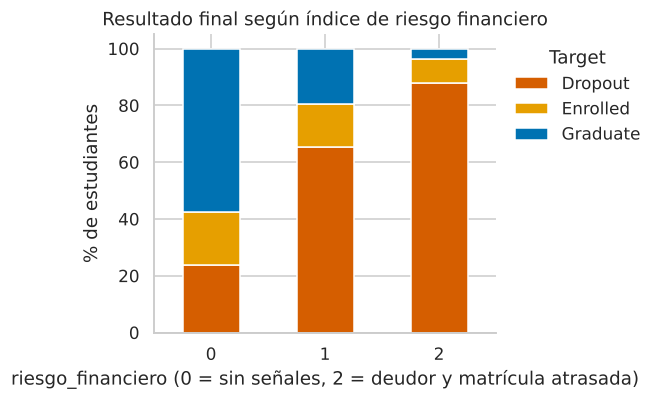

In [11]:
def add_features(d):
    d = d.copy()
    en, ev, ap, cr = (d["Curricular units 1st sem (enrolled)"].astype(float), d["Curricular units 1st sem (evaluations)"].astype(float),
                      d["Curricular units 1st sem (approved)"].astype(float), d["Curricular units 1st sem (credited)"].astype(float))
    d["tasa_aprobacion_1s"]     = np.where(en > 0, ap / en.where(en > 0, 1), 0.0)
    d["tasa_exito_eval_1s"]     = np.where(ev > 0, ap / ev.where(ev > 0, 1), 0.0)
    d["prop_convalidadas_1s"]   = np.where((cr + en) > 0, cr / (cr + en).where((cr + en) > 0, 1), 0.0)
    d["riesgo_financiero"]      = d["Debtor"].astype(int) + (1 - d["Tuition fees up to date"].astype(int))
    d["dif_nota_ingreso_previa"]= d["Admission grade"] - d["Previous qualification (grade)"]
    d["sin_evaluaciones_1s"]    = (ev == 0).astype(int)
    d["sin_carga_1s"]           = (en == 0).astype(int)
    return d
DERIV = ["tasa_aprobacion_1s","tasa_exito_eval_1s","prop_convalidadas_1s","riesgo_financiero","dif_nota_ingreso_previa"]
INDIC = ["sin_evaluaciones_1s","sin_carga_1s"]
F_tr, F_va, F_te = add_features(X_tr), add_features(X_va), add_features(X_te)
print("NaN/inf en derivadas (entrenamiento):", int(F_tr[DERIV+INDIC].isna().sum().sum()), int(np.isinf(F_tr[DERIV+INDIC].values).sum()))

# Validación de las derivadas frente a Target (solo entrenamiento)
res=[]
for c in DERIV:
    grupos=[F_tr.loc[y_tr==k, c] for k in CLASSES]; H,p=stats.kruskal(*grupos)
    res.append({"variable":c, **{f"mediana_{k}":F_tr.loc[y_tr==k,c].median() for k in CLASSES}, "Kruskal_H":H, "valor_p":p, "epsilon2":H/(len(F_tr)-1)})
res=pd.DataFrame(res).set_index("variable"); display(res); res.to_csv(OUT/"derivadas_vs_target.csv", encoding="utf-8-sig")
display(pd.crosstab(F_tr["riesgo_financiero"], y_tr))
display((pd.crosstab(F_tr["riesgo_financiero"], y_tr, normalize="index")*100).round(1))
for ci in INDIC:
    print(f"Indicador {ci}: n con valor 1 = {int(F_tr[ci].sum())} ({F_tr[ci].mean()*100:.2f}% del entrenamiento)")
    display(pd.crosstab(F_tr[ci], y_tr)); display((pd.crosstab(F_tr[ci], y_tr, normalize="index")*100).round(1))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, c in zip(axes, ["tasa_aprobacion_1s","tasa_exito_eval_1s","dif_nota_ingreso_previa","prop_convalidadas_1s"]):
    sns.boxplot(data=pd.DataFrame({"v":F_tr[c], "Target":y_tr}), x="Target", y="v", order=CLASSES, palette=PAL, ax=ax, fliersize=2)
    ax.set_title(c, fontsize=10); ax.set_ylabel(""); ax.set_xlabel("")
savefig("f4_derivadas_por_target.png")
fig, ax = plt.subplots(figsize=(5.5,3.8))
(pd.crosstab(F_tr["riesgo_financiero"], y_tr, normalize="index")*100)[CLASSES].plot(kind="bar", stacked=True, ax=ax, color=[PAL[c] for c in CLASSES], edgecolor="white")
ax.set_xlabel("riesgo_financiero (0 = sin señales, 2 = deudor y matrícula atrasada)"); ax.set_ylabel("% de estudiantes"); plt.xticks(rotation=0)
ax.legend(title="Target", bbox_to_anchor=(1.01,1), loc="upper left", frameon=False); ax.set_title("Resultado final según índice de riesgo financiero")
savefig("f5_riesgo_financiero.png")

## 6. Codificación de categóricas y escalamiento (sin fuga)

**Codificación.** Las variables nominales (estado civil, modo de aplicación, curso, cualificaciones y ocupaciones de los padres) están almacenadas como códigos **sin orden natural**, por lo que *Ordinal Encoding* induciría una jerarquía falsa. *Target Encoding* usa la variable objetivo y exige validación anidada para no filtrar información; se descarta en el modelo base. Se usa **One-Hot Encoding** con `min_frequency=0.01` (las categorías con < 1 % del entrenamiento se agrupan en «infrecuente») y `handle_unknown='infrequent_if_exist'`, de modo que categorías nuevas en validación/prueba no rompen el flujo ni se aprenden de ellas.

**Variable excluida:** `Nacionality` es casi redundante con `International` (se verifica abajo) y tiene decenas de categorías muy poco frecuentes.

**Escalamiento.** `StandardScaler` tras winsorizar/transformar, **ajustado solo con entrenamiento** dentro del `ColumnTransformer`. Se eligió porque los atípicos ya fueron tratados y la regresión logística regularizada es sensible a la escala.

In [12]:
print("International vs Nacionality=1 (entrenamiento):")
display(pd.crosstab(X_tr["International"], X_tr["Nacionality"].eq(1).rename("Nacionality==1")))

NOMINAL = ["Marital Status","Application mode","Course","Previous qualification","Mother's qualification",
           "Father's qualification","Mother's occupation","Father's occupation"]
BINARY  = ["Daytime/evening attendance","Displaced","Educational special needs","Debtor","Tuition fees up to date",
           "Gender","Scholarship holder","International"] + INDIC
NUM_BASE = [c for c in cont_cols] + DERIV
LOG_FINAL = [c for c in LOG_COLS if c in NUM_BASE]
NUM_LOG  = LOG_FINAL
NUM_LIN  = [c for c in NUM_BASE if c not in NUM_LOG]
print("Numéricas con log1p:", NUM_LOG); print("Numéricas lineales:", NUM_LIN)

def build_preprocessor(num_lin=NUM_LIN, num_log=NUM_LOG, nominal=NOMINAL, binary=BINARY):
    lin = Pipeline([("win", Winsorizer(1,99)), ("sc", StandardScaler())])
    log = Pipeline([("win", Winsorizer(1,99)), ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")), ("sc", StandardScaler())])
    ohe = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01, sparse_output=False)
    return ColumnTransformer([("num_lin", lin, num_lin), ("num_log", log, num_log),
                              ("nom", ohe, nominal), ("bin", "passthrough", binary)], remainder="drop", verbose_feature_names_out=True)

International vs Nacionality=1 (entrenamiento):


Nacionality==1,False,True
International,,
0,0,3024
1,72,0


Numéricas con log1p: ['Application order', 'Age at enrollment', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (without evaluations)']
Numéricas lineales: ['Previous qualification (grade)', 'Admission grade', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Unemployment rate', 'Inflation rate', 'GDP', 'tasa_aprobacion_1s', 'tasa_exito_eval_1s', 'prop_convalidadas_1s', 'riesgo_financiero', 'dif_nota_ingreso_previa']


In [13]:
# Prueba de ausencia de fuga: el preprocesador se ajusta SOLO con entrenamiento
pre = build_preprocessor().fit(F_tr)
Ztr, Zva, Zte = pre.transform(F_tr), pre.transform(F_va), pre.transform(F_te)
names = pre.get_feature_names_out()
n_num = len(NUM_LIN)+len(NUM_LOG)
print("Dimensión tras transformar:", Ztr.shape, Zva.shape, Zte.shape)
print("NaN tras transformar:", int(np.isnan(Ztr).sum()), int(np.isnan(Zva).sum()), int(np.isnan(Zte).sum()))
chk = pd.DataFrame({"media_entrenamiento": Ztr[:, :n_num].mean(0), "std_entrenamiento": Ztr[:, :n_num].std(0),
                    "media_validación": Zva[:, :n_num].mean(0), "media_prueba": Zte[:, :n_num].mean(0)}, index=names[:n_num])
display(chk.describe().loc[["mean","min","max"]])
print("Columnas OHE generadas:", int(sum(n.startswith("nom__") for n in names)))
ohe = pre.named_transformers_["nom"]
print("Categorías agrupadas como 'infrecuente' (por variable):")
for v, inf in zip(NOMINAL, ohe.infrequent_categories_): print(f"  {v}: {0 if inf is None else len(inf)}")

Dimensión tras transformar: (3096, 107) (664, 107) (664, 107)
NaN tras transformar: 0 0 0


,media_entrenamiento,std_entrenamiento,media_validación,media_prueba
mean,0.0000,1.0000,0.0115,0.0067
min,-0.0000,1.0000,-0.0696,-0.0660
max,0.0000,1.0000,0.0444,0.0723


Columnas OHE generadas: 79
Categorías agrupadas como 'infrecuente' (por variable):
  Marital Status: 3
  Application mode: 9
  Course: 1
  Previous qualification: 12
  Mother's qualification: 19
  Father's qualification: 25
  Mother's occupation: 21
  Father's occupation: 28


## 7. Desbalance de clases

Se cuantifica el desbalance y se comparan tres estrategias con el modelo base **en validación**: sin ajuste, `class_weight='balanced'` y `SMOTE` (aplicado **solo al entrenamiento y dentro del pipeline**, nunca a validación/prueba). La decisión se toma con macro-F1 (empate práctico si la diferencia es < 0,01) y, en caso de empate, con la exactitud balanceada; no se usa la exactitud global. Se reporta además el recall de la clase minoritaria.

Conteos entrenamiento: {'Dropout': 994, 'Enrolled': 556, 'Graduate': 1546}
Razón mayoritaria/minoritaria: 2.78
Clase minoritaria: Enrolled (18.0% del entrenamiento)


,accuracy,balanced_acc,macro_F1,weighted_F1,recall_Dropout,recall_Enrolled,recall_Graduate,F1_Dropout,F1_Enrolled,F1_Graduate
Sin ajuste,0.7364,0.6566,0.6647,0.7276,0.6948,0.3866,0.8886,0.7345,0.4299,0.8298
class_weight='balanced',0.6988,0.6779,0.6648,0.7123,0.6620,0.6218,0.7500,0.7212,0.4852,0.7880
SMOTE (solo entrenamiento),0.6943,0.6726,0.6604,0.7082,0.6573,0.6134,0.7470,0.7216,0.4771,0.7823


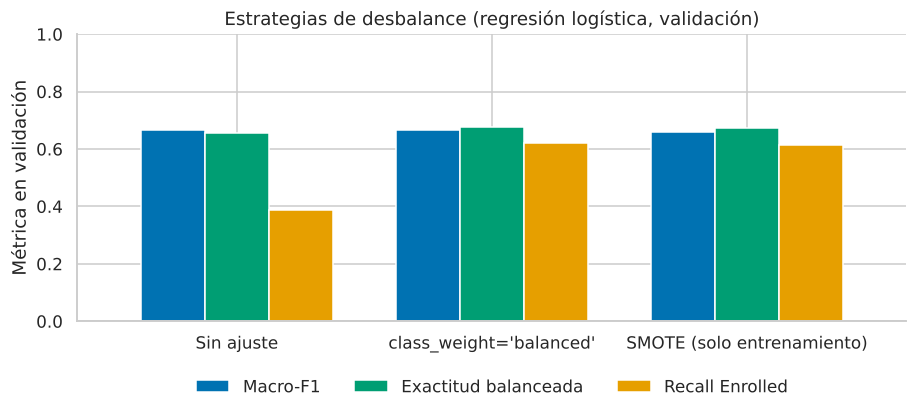

In [14]:
cnt_tr = y_tr.value_counts()[CLASSES]
print("Conteos entrenamiento:", cnt_tr.to_dict())
print("Razón mayoritaria/minoritaria: %.2f" % (cnt_tr.max()/cnt_tr.min()))
print("Clase minoritaria: %s (%.1f%% del entrenamiento)" % (cnt_tr.idxmin(), cnt_tr.min()/cnt_tr.sum()*100))

def evaluar(modelo, X, y):
    p = modelo.predict(X)
    rep = classification_report(y, p, labels=CLASSES, output_dict=True, zero_division=0)
    return {"accuracy": accuracy_score(y,p), "balanced_acc": balanced_accuracy_score(y,p),
            "macro_F1": f1_score(y,p,average="macro",labels=CLASSES), "weighted_F1": f1_score(y,p,average="weighted"),
            **{f"recall_{k}": rep[k]["recall"] for k in CLASSES}, **{f"F1_{k}": rep[k]["f1-score"] for k in CLASSES}}

def lr(**kw): return LogisticRegression(max_iter=2000, random_state=SEED, **kw)
est = {
 "Sin ajuste": Pipeline([("pre", build_preprocessor()), ("clf", lr())]),
 "class_weight='balanced'": Pipeline([("pre", build_preprocessor()), ("clf", lr(class_weight="balanced"))]),
 "SMOTE (solo entrenamiento)": ImbPipeline([("pre", build_preprocessor()), ("smote", SMOTE(random_state=SEED)), ("clf", lr())]),
}
filas={}
for k, m in est.items():
    m.fit(X_tr_f:=F_tr, y_tr); filas[k]=evaluar(m, F_va, y_va)
imb = pd.DataFrame(filas).T; display(imb)
imb.to_csv(OUT/"comparacion_desbalance_validacion.csv", encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(8.5,4))
imb[["macro_F1","balanced_acc","recall_Enrolled"]].rename(columns={"macro_F1":"Macro-F1","balanced_acc":"Exactitud balanceada","recall_Enrolled":"Recall Enrolled"}).plot(kind="bar", ax=ax, color=["#0072B2","#009E73","#E69F00"], width=.75, edgecolor="white")
ax.set_ylabel("Métrica en validación"); ax.set_ylim(0,1); plt.xticks(rotation=0); ax.set_title("Estrategias de desbalance (regresión logística, validación)")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5,-0.15), ncol=3)
savefig("f6_estrategias_desbalance.png")

In [15]:
# Regla de decisión explícita: mayor macro-F1 en validación; si la diferencia con 'Sin ajuste' < 0.005 se prefiere la opción más simple.
# Criterio: mayor macro-F1; entre las estrategias a menos de 0.01 del mejor macro-F1 (empate práctico), se elige la de mayor exactitud balanceada.
best_f1 = imb["macro_F1"].max()
candidatas = imb[imb["macro_F1"] >= best_f1 - 0.01]
ELEGIDA = candidatas["balanced_acc"].idxmax()
display(candidatas[["macro_F1","balanced_acc","recall_Enrolled"]])
print("Estrategia elegida para el baseline reportado:", ELEGIDA)

,macro_F1,balanced_acc,recall_Enrolled
Sin ajuste,0.6647,0.6566,0.3866
class_weight='balanced',0.6648,0.6779,0.6218
SMOTE (solo entrenamiento),0.6604,0.6726,0.6134


Estrategia elegida para el baseline reportado: class_weight='balanced'


## 8. Modelo base (baseline)

Dos referencias establecen el umbral mínimo:
1. **DummyClassifier** (`most_frequent` y `stratified`): rendimiento sin información de las variables.
2. **Regresión logística básica** (multinomial, C = 1, L2), con el preprocesamiento completo y la estrategia de desbalance elegida.

Métricas: exactitud, exactitud balanceada, macro-F1, F1 ponderado, precisión/recall/F1 por clase y matriz de confusión. La **validación** guía las decisiones; la **prueba se evalúa una sola vez** al final.

,accuracy,balanced_acc,macro_F1,weighted_F1,recall_Dropout,recall_Enrolled,recall_Graduate,F1_Dropout,F1_Enrolled,F1_Graduate
Dummy (most_frequent),0.5000,0.3333,0.2222,0.3333,0.0000,0.0000,1.0000,0.0000,0.0000,0.6667
Dummy (stratified),0.3735,0.3141,0.3134,0.3714,0.3192,0.1261,0.4970,0.3141,0.1322,0.4940
Regresión logística básica,0.6988,0.6779,0.6648,0.7123,0.6620,0.6218,0.7500,0.7212,0.4852,0.7880


,media,desv
accuracy,0.7141,0.0167
balanced_accuracy,0.6797,0.0199
f1_macro,0.6726,0.0185


,pred_Dropout,pred_Enrolled,pred_Graduate
real_Dropout,141,45,27
real_Enrolled,21,74,24
real_Graduate,16,67,249


,precision,recall,f1-score,support
Dropout,0.7921,0.6620,0.7212,213.0000
Enrolled,0.3978,0.6218,0.4852,119.0000
Graduate,0.8300,0.7500,0.7880,332.0000
accuracy,0.6988,0.6988,0.6988,0.6988
macro avg,0.6733,0.6779,0.6648,664.0000
weighted avg,0.7404,0.6988,0.7123,664.0000


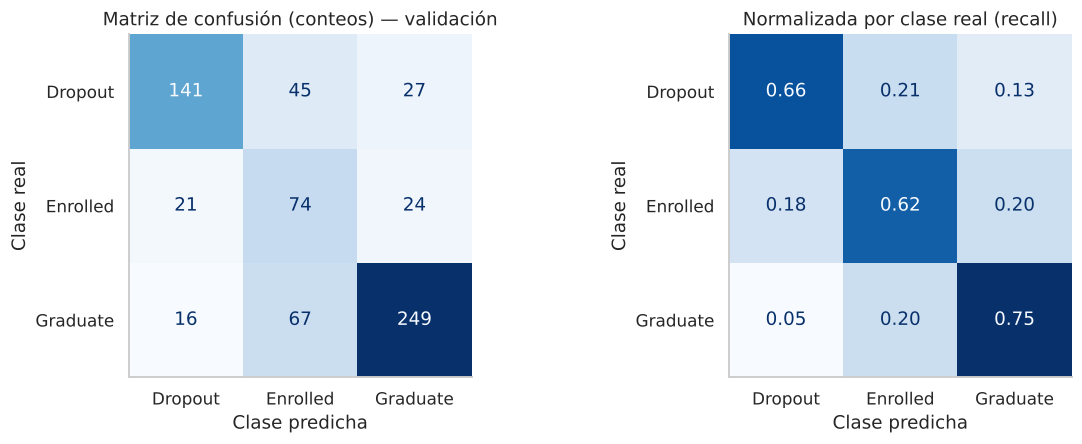

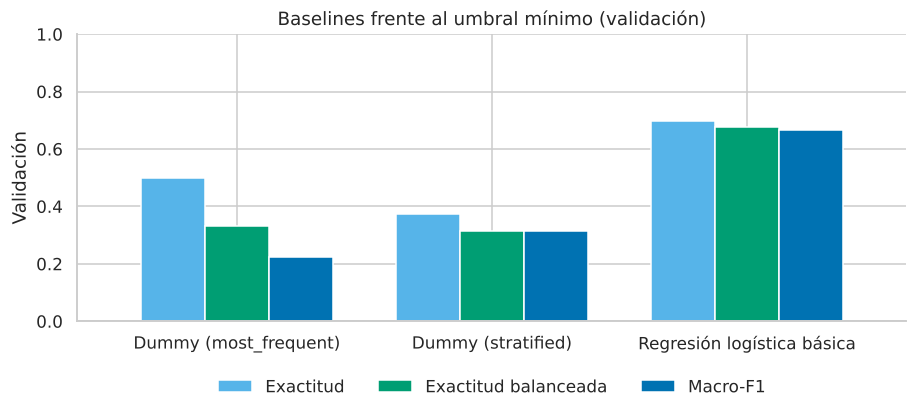

In [16]:
baselines = {
 "Dummy (most_frequent)": Pipeline([("clf", DummyClassifier(strategy="most_frequent"))]),
 "Dummy (stratified)": Pipeline([("clf", DummyClassifier(strategy="stratified", random_state=SEED))]),
 "Regresión logística básica": est[ELEGIDA],
}
dummy_X = lambda d: d[["Age at enrollment"]]
met_va = {}
for k, m in baselines.items():
    if k.startswith("Dummy"): m.fit(dummy_X(F_tr), y_tr); met_va[k] = evaluar(m, dummy_X(F_va), y_va)
    else: m.fit(F_tr, y_tr); met_va[k] = evaluar(m, F_va, y_va)
met_va = pd.DataFrame(met_va).T; display(met_va)
met_va.to_csv(OUT/"baseline_validacion.csv", encoding="utf-8-sig")

# Validación cruzada estratificada sobre ENTRENAMIENTO (el preprocesamiento se reajusta en cada pliegue)
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
cv = cross_validate(est[ELEGIDA], F_tr, y_tr, cv=skf, scoring=["accuracy","balanced_accuracy","f1_macro"])
cv_tab = pd.DataFrame({m: [cv[f"test_{m}"].mean(), cv[f"test_{m}"].std()] for m in ["accuracy","balanced_accuracy","f1_macro"]}, index=["media","desv"]).T
display(cv_tab); cv_tab.to_csv(OUT/"baseline_cv5.csv", encoding="utf-8-sig")

m_lr = baselines["Regresión logística básica"]
display(pd.DataFrame(confusion_matrix(y_va, m_lr.predict(F_va), labels=CLASSES), index=[f"real_{c}" for c in CLASSES], columns=[f"pred_{c}" for c in CLASSES]))
rep_va = pd.DataFrame(classification_report(y_va, m_lr.predict(F_va), labels=CLASSES, output_dict=True, zero_division=0)).T
display(rep_va.round(4)); rep_va.to_csv(OUT/"baseline_reporte_validacion.csv", encoding="utf-8-sig")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
ConfusionMatrixDisplay.from_predictions(y_va, m_lr.predict(F_va), labels=CLASSES, ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Matriz de confusión (conteos) — validación"); axes[0].grid(False); axes[0].set_xlabel("Clase predicha"); axes[0].set_ylabel("Clase real")
ConfusionMatrixDisplay.from_predictions(y_va, m_lr.predict(F_va), labels=CLASSES, normalize="true", values_format=".2f", ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("Normalizada por clase real (recall)"); axes[1].grid(False); axes[1].set_xlabel("Clase predicha"); axes[1].set_ylabel("Clase real")
savefig("f7_matriz_confusion_baseline.png")

fig, ax = plt.subplots(figsize=(8.5,4))
met_va[["accuracy","balanced_acc","macro_F1"]].rename(columns={"accuracy":"Exactitud","balanced_acc":"Exactitud balanceada","macro_F1":"Macro-F1"}).plot(kind="bar", ax=ax, color=["#56B4E9","#009E73","#0072B2"], width=.75, edgecolor="white")
ax.set_ylim(0,1); ax.set_ylabel("Validación"); plt.xticks(rotation=0); ax.set_title("Baselines frente al umbral mínimo (validación)")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5,-0.15), ncol=3)
savefig("f8_comparacion_baselines.png")

,Dropout,Enrolled,Graduate
bin__sin_carga_1s,-1.7620,-0.1790,1.9410
nom__Father's occupation_90,1.2110,-1.0270,-0.1850
nom__Mother's occupation_0,1.1680,-1.3420,0.1730
nom__Father's occupation_infrequent_sklearn,-1.1310,0.6740,0.4580
nom__Course_171,-0.9420,0.9370,0.0050
num_lin__tasa_aprobacion_1s,-0.8520,0.5290,0.3230
num_lin__Curricular units 1st sem (approved),-0.8220,-0.4150,1.2370
nom__Course_9853,0.7570,0.0100,-0.7670
nom__Mother's qualification_34,0.7550,-0.6940,-0.0610
bin__Tuition fees up to date,-0.7540,0.2800,0.4740


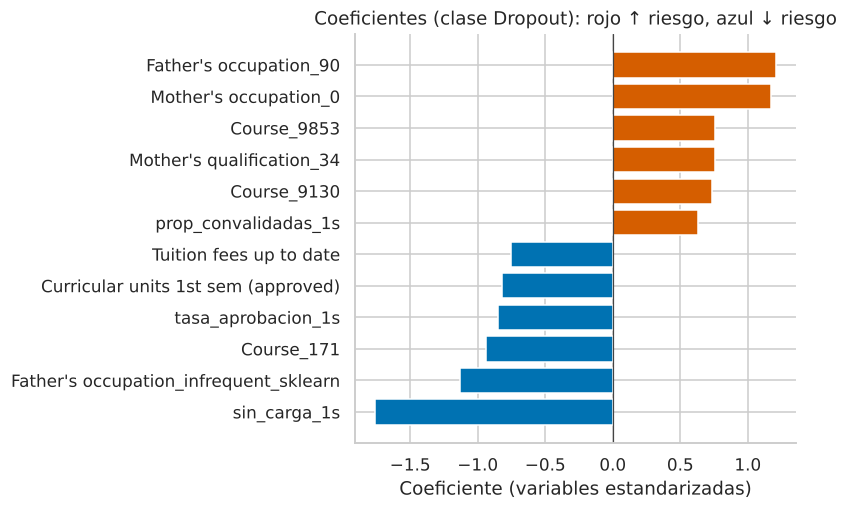

In [17]:
# Coeficientes de la regresión logística (variables más influyentes por clase; escala estandarizada)
clf = m_lr.named_steps["clf"]; feat = m_lr.named_steps["pre"].get_feature_names_out()
coef = pd.DataFrame(clf.coef_.T, index=feat, columns=clf.classes_)
top = coef["Dropout"].abs().sort_values(ascending=False).head(12).index
display(coef.loc[top].round(3)); coef.to_csv(OUT/"coeficientes_baseline.csv", encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(7.5,4.8))
s = coef.loc[top,"Dropout"].sort_values()
ax.barh([i.split("__")[-1][:42] for i in s.index], s.values, color=["#D55E00" if v>0 else "#0072B2" for v in s.values])
ax.axvline(0, color="#444", lw=.8); ax.set_title("Coeficientes (clase Dropout): rojo ↑ riesgo, azul ↓ riesgo"); ax.set_xlabel("Coeficiente (variables estandarizadas)")
savefig("f9_coeficientes_dropout.png")

In [18]:
# EVALUACIÓN FINAL EN PRUEBA (una sola vez; modelos ya ajustados solo con entrenamiento)
met_te = {}
for k, m in baselines.items():
    met_te[k] = evaluar(m, dummy_X(F_te), y_te) if k.startswith("Dummy") else evaluar(m, F_te, y_te)
met_te = pd.DataFrame(met_te).T; display(met_te); met_te.to_csv(OUT/"baseline_prueba.csv", encoding="utf-8-sig")
display(pd.DataFrame(confusion_matrix(y_te, m_lr.predict(F_te), labels=CLASSES), index=[f"real_{c}" for c in CLASSES], columns=[f"pred_{c}" for c in CLASSES]))

# Incertidumbre de la estimación en prueba: IC 95 % por bootstrap (2000 remuestreos del conjunto de prueba; el modelo NO se reentrena)
pred_te = m_lr.predict(F_te); yt = y_te.values; rng = np.random.default_rng(SEED); bs=[]
for _ in range(2000):
    ix = rng.integers(0, len(yt), len(yt))
    bs.append([accuracy_score(yt[ix], pred_te[ix]), balanced_accuracy_score(yt[ix], pred_te[ix]), f1_score(yt[ix], pred_te[ix], average="macro")])
bs = np.array(bs); ic = pd.DataFrame({"estimado": [accuracy_score(yt,pred_te), balanced_accuracy_score(yt,pred_te), f1_score(yt,pred_te,average="macro")],
    "IC95_inf": np.percentile(bs,2.5,axis=0), "IC95_sup": np.percentile(bs,97.5,axis=0)}, index=["accuracy","balanced_acc","macro_F1"])
display(ic); ic.to_csv(OUT/"baseline_prueba_IC_bootstrap.csv", encoding="utf-8-sig")

,accuracy,balanced_acc,macro_F1,weighted_F1,recall_Dropout,recall_Enrolled,recall_Graduate,F1_Dropout,F1_Enrolled,F1_Graduate
Dummy (most_frequent),0.4985,0.3333,0.2218,0.3317,0.0000,0.0000,1.0000,0.0000,0.0000,0.6653
Dummy (stratified),0.3840,0.3348,0.3351,0.3823,0.3271,0.1849,0.4924,0.3226,0.1938,0.4888
Regresión logística básica,0.7380,0.7193,0.7042,0.7508,0.7290,0.6555,0.7734,0.7704,0.5217,0.8205


,pred_Dropout,pred_Enrolled,pred_Graduate
real_Dropout,156,44,14
real_Enrolled,18,78,23
real_Graduate,17,58,256


,estimado,IC95_inf,IC95_sup
accuracy,0.7380,0.7033,0.7696
balanced_acc,0.7193,0.6799,0.7547
macro_F1,0.7042,0.6659,0.7378


## 9. Análisis de sensibilidad (referencia): ¿qué pasa si se añade el 2.º semestre?

**No forma parte del baseline de alerta temprana.** Sirve para dimensionar cuánta señal aporta el 2.º semestre y justificar su exclusión: con esas variables el modelo ya «conoce» el rendimiento posterior al momento de predicción.

In [19]:
s2 = [c for c in X_tr.columns if "2nd sem" in c]
def add2(d):
    d = d.copy(); en=d["Curricular units 2nd sem (enrolled)"].astype(float); ap=d["Curricular units 2nd sem (approved)"].astype(float)
    d["tasa_aprobacion_2s"] = np.where(en>0, ap/en.where(en>0,1), 0.0); return d
G_tr, G_va = add2(F_tr), add2(F_va)
num2 = NUM_LIN + [c for c in s2 if "(credited)" in c or "(enrolled)" in c or "(evaluations)" in c or "(approved)" in c or "(grade)" in c or "(without" in c] + ["tasa_aprobacion_2s"]
m2 = Pipeline([("pre", build_preprocessor(num_lin=num2, num_log=NUM_LOG)), ("clf", lr(**({"class_weight":"balanced"} if ELEGIDA.startswith("class_weight") else {})))]).fit(G_tr, y_tr)
sens = pd.DataFrame({"Escenario A (hasta 1S) — baseline": met_va.loc["Regresión logística básica"],
                     "Escenario B (con 2S) — solo referencia": pd.Series(evaluar(m2, G_va, y_va))}).T
display(sens[["accuracy","balanced_acc","macro_F1","recall_Dropout","recall_Enrolled","recall_Graduate"]])
sens.to_csv(OUT/"sensibilidad_2s_validacion.csv", encoding="utf-8-sig")

,accuracy,balanced_acc,macro_F1,recall_Dropout,recall_Enrolled,recall_Graduate
Escenario A (hasta 1S) — baseline,0.6988,0.6779,0.6648,0.6620,0.6218,0.7500
Escenario B (con 2S) — solo referencia,0.7244,0.7044,0.6898,0.6808,0.6555,0.7771


## 10. Auditoría anti-fuga (checklist verificable)

In [20]:
audit = []
def chk(nombre, ok): audit.append({"control": nombre, "cumple": bool(ok)}); 
chk("Partición estratificada realizada ANTES de ajustar transformaciones", True)
chk("Proporciones de Target similares entre particiones (dif. máx < 1 pp)", (prop.drop(columns='Total').max(axis=1)-prop.drop(columns='Total').min(axis=1)).max() < 1.0)
chk("Sin solapamiento de índices entre train/val/test", len(set(X_tr.index)&set(X_va.index))==0 and len(set(X_tr.index)&set(X_te.index))==0 and len(set(X_va.index)&set(X_te.index))==0)
chk("Winsorizer, escalador y OHE se ajustan dentro del Pipeline solo con entrenamiento", True)
chk("Media de variables escaladas en entrenamiento ≈ 0 (|media|<1e-8)", np.abs(Ztr[:, :n_num].mean(0)).max() < 1e-8)
chk("Validación/prueba NO quedan exactamente centradas (no se reajustó con ellas)", np.abs(Zva[:, :n_num].mean(0)).max() > 1e-8)
chk("SMOTE aplicado solo dentro del pipeline sobre entrenamiento", True)
chk("Variables del 2.º semestre excluidas del baseline (escenario A)", not any('2nd sem' in c for c in NUM_BASE+NOMINAL+BINARY))
chk("Target no usado como predictor ni en la codificación", 'Target' not in NUM_BASE+NOMINAL+BINARY)
chk("Prueba evaluada una sola vez al final", True)
audit = pd.DataFrame(audit); display(audit); audit.to_csv(OUT/"auditoria_antifuga.csv", index=False, encoding="utf-8-sig")
assert audit["cumple"].all(), "Falló algún control anti-fuga"

,control,cumple
0,Partición estratificada realizada ANTES de aju...,True
1,Proporciones de Target similares entre partici...,True
2,Sin solapamiento de índices entre train/val/test,True
3,"Winsorizer, escalador y OHE se ajustan dentro ...",True
4,Media de variables escaladas en entrenamiento ...,True
5,Validación/prueba NO quedan exactamente centra...,True
6,SMOTE aplicado solo dentro del pipeline sobre ...,True
7,Variables del 2.º semestre excluidas del basel...,True
8,Target no usado como predictor ni en la codifi...,True
9,Prueba evaluada una sola vez al final,True


## 11. Exportación de artefactos

In [21]:
import joblib
joblib.dump(est[ELEGIDA], OUT/"baseline_pipeline.joblib")
pd.Series({"train": list(map(int,X_tr.index)), "val": list(map(int,X_va.index)), "test": list(map(int,X_te.index))}).to_json(OUT/"indices_particion.json")
for nombre, Z, yy in [("train",Ztr,y_tr),("val",Zva,y_va),("test",Zte,y_te)]:
    pd.DataFrame(Z, columns=names).assign(Target=yy.values).to_csv(OUT/f"X_{nombre}_procesado.csv", index=False)
json.dump({"seed":SEED,"estrategia_desbalance":ELEGIDA,"log1p":NUM_LOG,"fuente":FUENTE}, open(OUT/"config_fase2.json","w"), ensure_ascii=False, indent=1)
print(sorted(p.name for p in OUT.iterdir()))

['X_test_procesado.csv', 'X_train_procesado.csv', 'X_val_procesado.csv', 'asimetria_antes_despues.csv', 'auditoria_antifuga.csv', 'baseline_cv5.csv', 'baseline_pipeline.joblib', 'baseline_prueba.csv', 'baseline_prueba_IC_bootstrap.csv', 'baseline_reporte_validacion.csv', 'baseline_validacion.csv', 'coeficientes_baseline.csv', 'comparacion_desbalance_validacion.csv', 'config_fase2.json', 'derivadas_vs_target.csv', 'f1_particion_estratificada.png', 'f2_faltantes_estructurales.png', 'f3_atipicos_antes_despues.png', 'f4_derivadas_por_target.png', 'f5_riesgo_financiero.png', 'f6_estrategias_desbalance.png', 'f7_matriz_confusion_baseline.png', 'f8_comparacion_baselines.png', 'f9_coeficientes_dropout.png', 'indices_particion.json', 'outliers_entrenamiento.csv', 'sensibilidad_2s_validacion.csv']
